# PAI Project 1: Exploratory Data Analysis
## Smog (PM2.5) in Lahore, Islamabad, Karachi and Peshawar

**Problem.** Smog is a serious health issue in Pakistani cities, especially in winter, but people cannot easily get a reliable forecast of tomorrow's PM2.5 level, and ground-sensor coverage is limited.

**Data.** Hourly PM2.5 / PM10 (Open-Meteo Air Quality API, CAMS model estimates) and hourly weather (Open-Meteo Historical Weather API), August 2022 to present, local time (Asia/Karachi). The data was extracted, validated (Pydantic), cleaned (pandas) and loaded into `data/smog.db` by `pipeline.py`. **Run `python pipeline.py` before this notebook.**

**Structured EDA plan**
1. Data overview
2. Data quality checks (missing values, duplicates, impossible values, time gaps)
3. Distributions
4. Seasonal and hourly patterns of PM2.5
5. Relationships between PM2.5 and weather, with city comparison
6. Autocorrelation / lag analysis for next-day forecasting

In [1]:
import json
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("data/smog.db")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

CITY_ORDER = ["Lahore", "Islamabad", "Karachi", "Peshawar"]
CITY_COLORS = {"Lahore": "#d62728", "Islamabad": "#1f77b4", "Karachi": "#2ca02c", "Peshawar": "#9467bd"}
WEATHER_VARS = ["temperature_2m", "relative_humidity_2m", "dew_point_2m",
                "surface_pressure", "wind_speed_10m", "wind_direction_10m", "precipitation"]
NUMERIC_COLS = ["pm2_5", "pm10"] + WEATHER_VARS
WHO_24H_PM25 = 15  # WHO 2021 guideline for 24-hour mean PM2.5, µg/m³

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.2f}".format)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

conn = sqlite3.connect(DB_PATH)
df = pd.read_sql("SELECT * FROM clean_hourly", conn, parse_dates=["timestamp"])
raw_weather = pd.read_sql("SELECT * FROM raw_weather", conn)
raw_air = pd.read_sql("SELECT * FROM raw_air_quality", conn)
rejected = pd.read_sql("SELECT * FROM rejected_rows", conn)
pipeline_log = pd.read_sql("SELECT * FROM pipeline_log", conn)
print(f"clean_hourly: {len(df):,} rows | raw_weather: {len(raw_weather):,} | "
      f"raw_air_quality: {len(raw_air):,} | rejected_rows: {len(rejected):,}")

clean_hourly: 148,105 rows | raw_weather: 148,416 | raw_air_quality: 148,416 | rejected_rows: 6


## Step 1: Data overview
What is in the clean table, which columns and types it has, and what period each city covers.

In [2]:
print("Shape:", df.shape)
df.dtypes.to_frame("dtype").T

Shape: (148105, 19)


,city,timestamp,pm2_5,pm10,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,wind_direction_10m,precipitation,hour,day_of_week,month,year,season,is_smog_season,aqi_category,is_interpolated
dtype,str,datetime64[us],float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64,str,int64,str,int64


In [3]:
df.head()

,city,timestamp,pm2_5,pm10,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,wind_direction_10m,precipitation,hour,day_of_week,month,year,season,is_smog_season,aqi_category,is_interpolated
0,Islamabad,2022-08-04 05:00:00,50.20,72.40,24.80,78.00,20.70,944.70,7.30,9.00,0.00,5,3,8,2022,Summer,0,Unhealthy for Sensitive Groups,0
1,Islamabad,2022-08-04 06:00:00,49.90,71.90,26.20,77.00,21.70,945.10,3.70,349.00,0.00,6,3,8,2022,Summer,0,Unhealthy for Sensitive Groups,0
2,Islamabad,2022-08-04 07:00:00,51.80,74.50,28.30,68.00,21.80,945.60,3.20,333.00,0.00,7,3,8,2022,Summer,0,Unhealthy for Sensitive Groups,0
3,Islamabad,2022-08-04 08:00:00,51.00,73.80,29.60,64.00,22.00,946.00,1.10,342.00,0.00,8,3,8,2022,Summer,0,Unhealthy for Sensitive Groups,0
4,Islamabad,2022-08-04 09:00:00,49.10,71.20,30.90,60.00,22.10,946.00,2.00,225.00,0.00,9,3,8,2022,Summer,0,Unhealthy for Sensitive Groups,0


In [4]:
overview = df.groupby("city").agg(
    rows=("pm2_5", "size"),
    first_hour=("timestamp", "min"),
    last_hour=("timestamp", "max"),
).reindex(CITY_ORDER)
overview["days"] = (overview["last_hour"] - overview["first_hour"]).dt.days + 1
overview

,rows,first_hour,last_hour,days
city,,,,
Lahore,37027,2022-08-04 05:00:00,2026-10-24 23:00:00,1543
Islamabad,37024,2022-08-04 05:00:00,2026-10-24 23:00:00,1543
Karachi,37027,2022-08-04 05:00:00,2026-10-24 23:00:00,1543
Peshawar,37027,2022-08-04 05:00:00,2026-10-24 23:00:00,1543


In [5]:
df[NUMERIC_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
pm2_5,"148,105.00",43.89,33.44,0.40,23.20,34.80,52.60,448.90
pm10,"148,105.00",68.41,49.81,0.50,38.50,56.00,81.70,890.30
temperature_2m,"148,105.00",23.73,7.94,-1.40,18.10,25.30,29.40,46.50
relative_humidity_2m,"148,105.00",62.90,21.44,4.00,47.00,65.00,81.00,100.00
dew_point_2m,"148,105.00",15.06,8.18,-23.90,8.60,15.30,23.00,29.10
surface_pressure,"148,105.00",977.81,21.96,934.40,958.70,976.30,995.10,"1,024.40"
wind_speed_10m,"148,105.00",8.20,5.92,0.00,4.00,6.80,10.70,46.60
wind_direction_10m,"148,105.00",194.19,111.63,1.00,84.00,230.00,293.00,360.00
precipitation,"148,105.00",0.08,0.59,0.00,0.00,0.00,0.00,21.50


In [6]:
# PM2.5 summary by city
df.groupby("city")["pm2_5"].describe(percentiles=[.5, .9, .99]).reindex(CITY_ORDER)

,count,mean,std,min,50%,90%,99%,max
city,,,,,,,,
Lahore,"37,027.00",69.87,48.58,0.50,54.80,137.40,243.10,365.10
Islamabad,"37,024.00",38.29,20.38,0.60,34.20,64.70,107.10,170.90
Karachi,"37,027.00",30.09,18.62,0.40,25.00,50.90,97.80,448.90
Peshawar,"37,027.00",37.31,20.26,0.40,33.80,63.60,103.60,156.50


## Step 2: Data quality checks
Checked on the **raw** tables (before cleaning) to show what the pipeline had to fix, and on the clean table to confirm it worked.

### 2a. Pipeline funnel

In [7]:
pipeline_log[["step", "value"]].set_index("step")

,value
step,
raw_weather_rows,148416
raw_air_quality_rows,148416
merged_rows,148416
valid_rows,148410
rejected_rows,6
duplicates_removed,0
missing_hours_added_to_grid,6
values_interpolated,27
rows_dropped_no_pm25,311


### 2b. Missing values in the raw data

,pm2_5,pm10,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,wind_direction_10m,precipitation
city,,,,,,,,,
Lahore,0.21,0.21,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Islamabad,0.21,0.21,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Karachi,0.21,0.21,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Peshawar,0.21,0.21,0.00,0.00,0.00,0.00,0.00,0.00,0.00


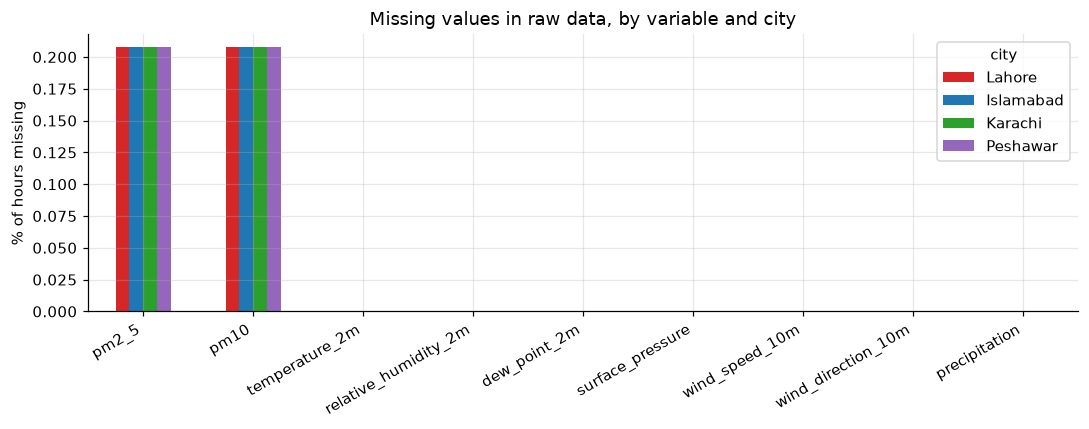

In [8]:
raw = pd.merge(raw_weather.drop(columns="extracted_at"),
               raw_air.drop(columns="extracted_at"),
               on=["city", "timestamp"], how="outer")
missing_pct = (raw.groupby("city")[NUMERIC_COLS]
                  .apply(lambda g: g.isna().mean() * 100)
                  .reindex(CITY_ORDER))
display(missing_pct.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
missing_pct.T.plot(kind="bar", ax=ax, color=[CITY_COLORS[c] for c in CITY_ORDER])
ax.set_ylabel("% of hours missing")
ax.set_title("Missing values in raw data, by variable and city")
plt.xticks(rotation=30, ha="right")
save(fig, "02_missing_values_raw")

### 2c. Duplicates

In [9]:
print("Duplicate (city, hour) rows in raw weather:     ", raw_weather.duplicated(["city", "timestamp"]).sum())
print("Duplicate (city, hour) rows in raw air quality: ", raw_air.duplicated(["city", "timestamp"]).sum())
print("Duplicate (city, hour) rows in clean table:     ", df.duplicated(["city", "timestamp"]).sum())

Duplicate (city, hour) rows in raw weather:      0
Duplicate (city, hour) rows in raw air quality:  0
Duplicate (city, hour) rows in clean table:      0


### 2d. Impossible values (rejected by Pydantic)
Rules: PM2.5 0 to 1000, PM10 0 to 2000, temperature −30 to 60 °C, humidity 0 to 100 %, pressure 850 to 1100 hPa, wind speed ≥ 0, precipitation ≥ 0, plus two physical checks: PM2.5 ≤ PM10 and dew point ≤ temperature.

In [10]:
if len(rejected) == 0:
    print("No records were rejected.")
else:
    reasons = (rejected.assign(errors=rejected["errors"].map(json.loads))
                       .explode("errors"))
    reasons["field"] = reasons["errors"].map(lambda e: e["field"])
    reasons["message"] = reasons["errors"].map(lambda e: e["message"])
    display(reasons.groupby(["city", "field", "message"]).size()
                   .rename("count").reset_index()
                   .sort_values("count", ascending=False))
    display(rejected[["city", "timestamp", "errors"]].head(10))

,city,field,message,count
0,Islamabad,record,"Value error, pm2_5 is greater than pm10",6


,city,timestamp,errors
0,Islamabad,2023-12-15 05:00:00,"[{""field"": ""record"", ""message"": ""Value error, ..."
1,Islamabad,2023-12-15 06:00:00,"[{""field"": ""record"", ""message"": ""Value error, ..."
2,Islamabad,2023-12-15 07:00:00,"[{""field"": ""record"", ""message"": ""Value error, ..."
3,Islamabad,2023-12-15 08:00:00,"[{""field"": ""record"", ""message"": ""Value error, ..."
4,Islamabad,2023-12-15 09:00:00,"[{""field"": ""record"", ""message"": ""Value error, ..."
5,Islamabad,2023-12-15 10:00:00,"[{""field"": ""record"", ""message"": ""Value error, ..."


### 2e. Time gaps
Every city should have one row per hour. We compare the hours we expected with the hours we got, and check the clean table for any jumps larger than one hour.

In [11]:
raw_ts = raw.assign(timestamp=pd.to_datetime(raw["timestamp"]))
gap_rows = []
for city, g in raw_ts.groupby("city"):
    expected = pd.date_range(g["timestamp"].min(), g["timestamp"].max(), freq="h")
    clean_city = df[df["city"] == city].sort_values("timestamp")
    steps = clean_city["timestamp"].diff().dropna()
    gap_rows.append({
        "city": city,
        "expected_hours": len(expected),
        "hours_in_raw": g["timestamp"].nunique(),
        "hours_missing_in_raw": len(expected.difference(g["timestamp"])),
        "gaps_>1h_in_clean": int((steps > pd.Timedelta(hours=1)).sum()),
        "largest_gap_in_clean": steps.max(),
        "interpolated_rows": int(clean_city["is_interpolated"].sum()),
    })
pd.DataFrame(gap_rows).set_index("city").reindex(CITY_ORDER)

,expected_hours,hours_in_raw,hours_missing_in_raw,gaps_>1h_in_clean,largest_gap_in_clean,interpolated_rows
city,,,,,,
Lahore,37104,37104,0,0,0 days 01:00:00,0
Islamabad,37104,37104,0,1,0 days 04:00:00,3
Karachi,37104,37104,0,0,0 days 01:00:00,0
Peshawar,37104,37104,0,0,0 days 01:00:00,0


In [12]:
# Where are the remaining gaps (if any) in the clean data?
for city in CITY_ORDER:
    s = df[df["city"] == city].sort_values("timestamp")
    jumps = s.loc[s["timestamp"].diff() > pd.Timedelta(hours=1), "timestamp"]
    print(f"{city}: {len(jumps)} gaps", "" if jumps.empty else f"(first at {jumps.iloc[0]})")

Lahore: 0 gaps 
Islamabad: 1 gaps (first at 2023-12-15 11:00:00)
Karachi: 0 gaps 
Peshawar: 0 gaps 


## Step 3: Distributions

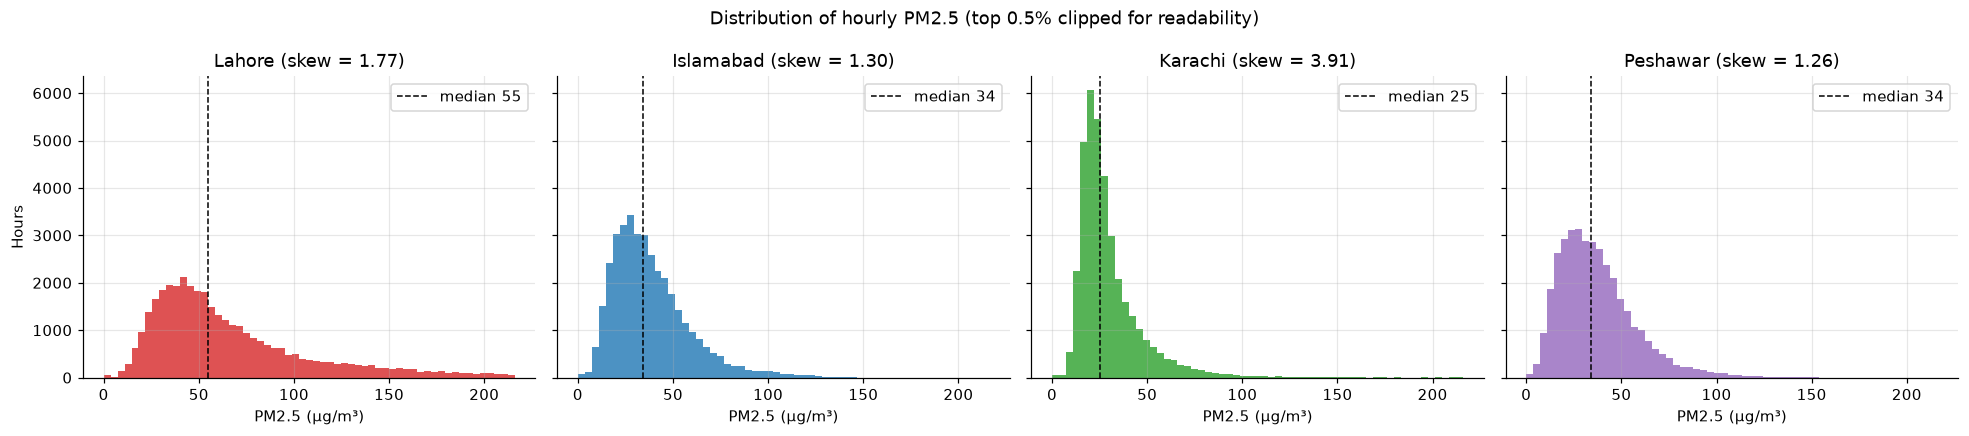

In [13]:
fig, axes = plt.subplots(1, len(CITY_ORDER), figsize=(18, 4), sharey=True)
upper = df["pm2_5"].quantile(0.995)
bins = np.linspace(0, upper, 60)
for ax, city in zip(axes, CITY_ORDER):
    s = df.loc[df["city"] == city, "pm2_5"]
    ax.hist(s, bins=bins, color=CITY_COLORS[city], alpha=0.8)
    ax.axvline(s.median(), color="black", ls="--", lw=1, label=f"median {s.median():.0f}")
    ax.set_title(f"{city} (skew = {s.skew():.2f})")
    ax.set_xlabel("PM2.5 (µg/m³)")
    ax.legend()
axes[0].set_ylabel("Hours")
fig.suptitle("Distribution of hourly PM2.5 (top 0.5% clipped for readability)")
save(fig, "03_pm25_distribution")

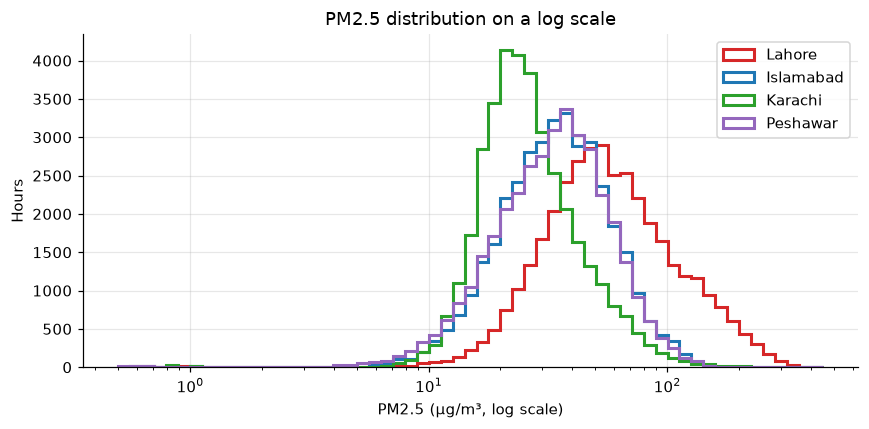

In [14]:
# log scale makes the right-skewed shape easier to compare
fig, ax = plt.subplots(figsize=(8, 4))
log_bins = np.logspace(np.log10(max(df["pm2_5"].min(), 0.5)), np.log10(df["pm2_5"].max()), 60)
for city in CITY_ORDER:
    ax.hist(df.loc[df["city"] == city, "pm2_5"], bins=log_bins, histtype="step",
            lw=2, color=CITY_COLORS[city], label=city)
ax.set_xscale("log")
ax.set_xlabel("PM2.5 (µg/m³, log scale)")
ax.set_ylabel("Hours")
ax.set_title("PM2.5 distribution on a log scale")
ax.legend()
save(fig, "03_pm25_distribution_log")

aqi_category,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
city,,,,,,
Lahore,0.30,22.00,28.40,36.80,10.80,1.60
Islamabad,1.10,51.70,30.50,16.60,0.20,0.00
Karachi,0.70,75.20,16.30,7.40,0.40,0.00
Peshawar,1.90,51.60,30.50,15.70,0.30,0.00


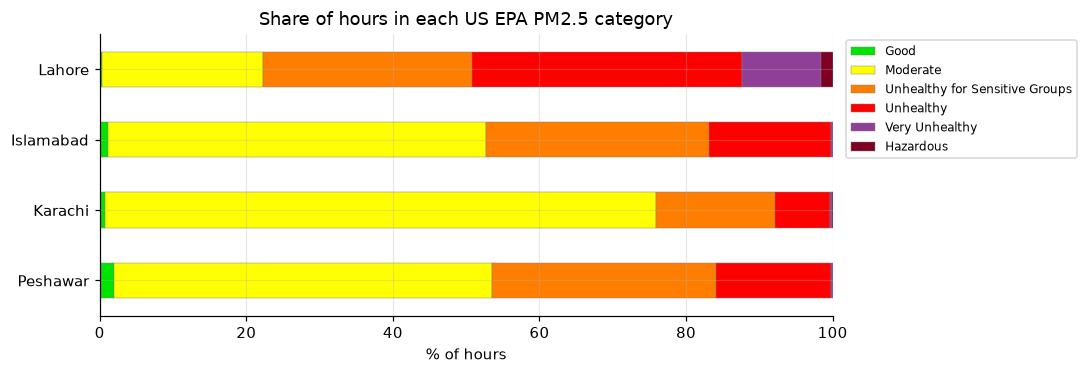

In [15]:
aqi_order = ["Good", "Moderate", "Unhealthy for Sensitive Groups",
             "Unhealthy", "Very Unhealthy", "Hazardous"]
aqi_colors = ["#00e400", "#ffff00", "#ff7e00", "#ff0000", "#8f3f97", "#7e0023"]
aqi_share = (pd.crosstab(df["city"], df["aqi_category"], normalize="index") * 100
               ).reindex(index=CITY_ORDER, columns=aqi_order, fill_value=0)
display(aqi_share.round(1))

fig, ax = plt.subplots(figsize=(10, 3.5))
aqi_share.plot(kind="barh", stacked=True, color=aqi_colors, ax=ax, edgecolor="grey", lw=0.3)
ax.set_xlabel("% of hours")
ax.set_ylabel("")
ax.set_title("Share of hours in each US EPA PM2.5 category")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.invert_yaxis()
save(fig, "03_aqi_categories")

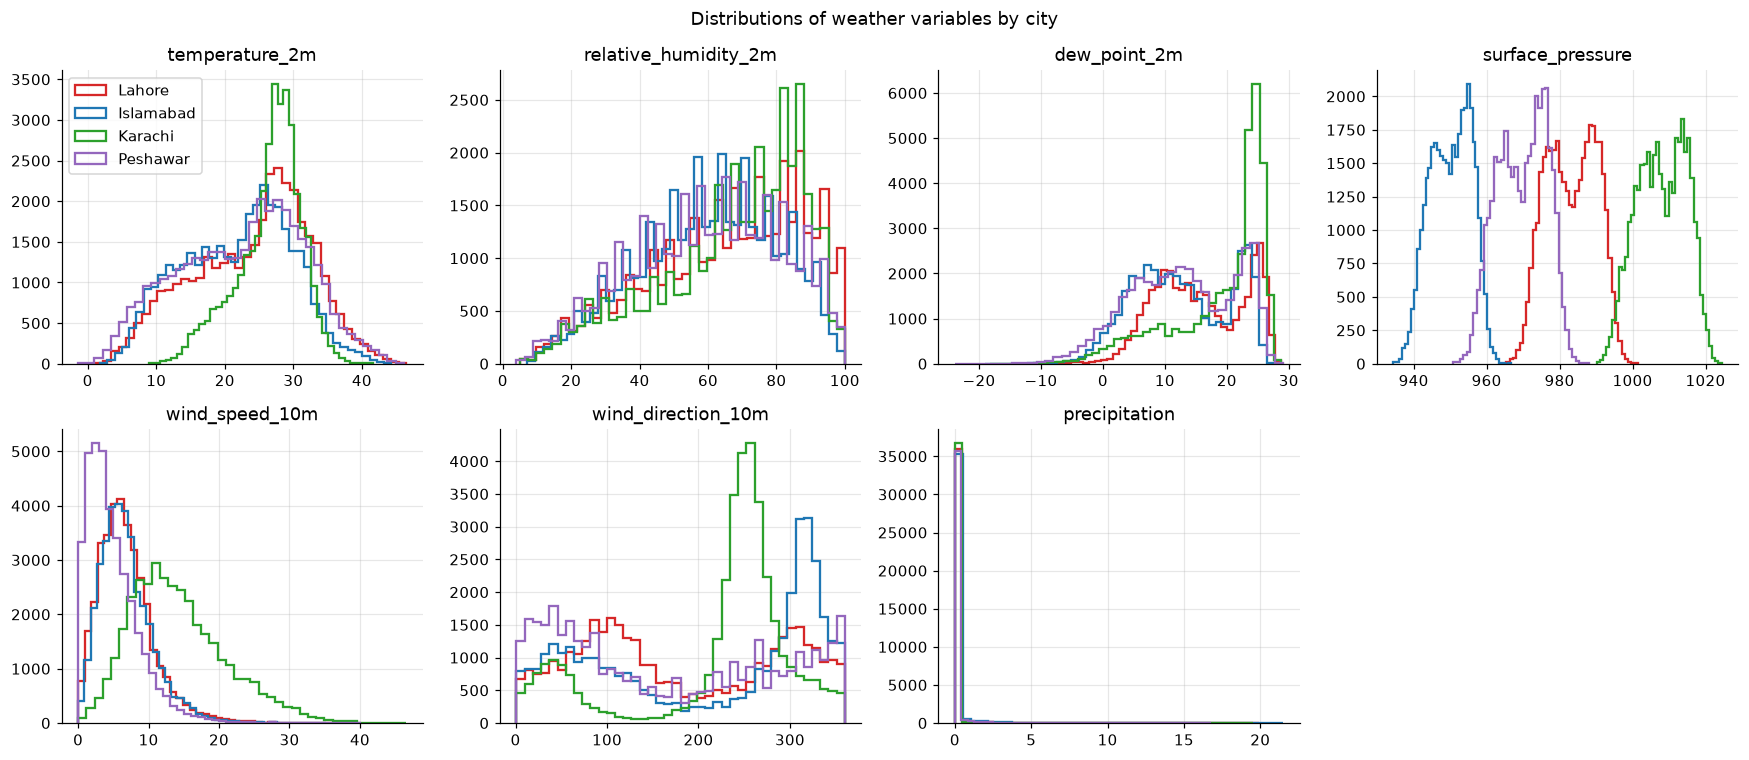

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, WEATHER_VARS):
    for city in CITY_ORDER:
        ax.hist(df.loc[df["city"] == city, col].dropna(), bins=40, histtype="step",
                lw=1.5, color=CITY_COLORS[city], label=city)
    ax.set_title(col)
axes.flat[0].legend()
axes.flat[-1].axis("off")
fig.suptitle("Distributions of weather variables by city")
save(fig, "03_weather_distributions")

## Step 4: Seasonal and hourly patterns of PM2.5

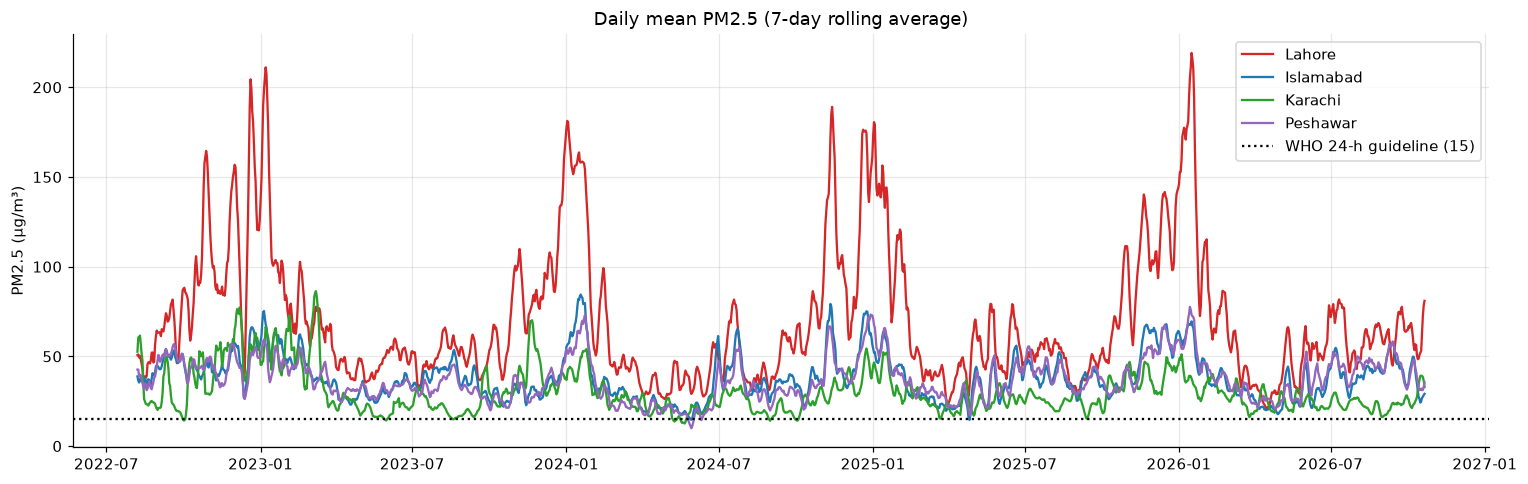

In [17]:
daily = (df.set_index("timestamp").groupby("city")["pm2_5"]
           .resample("D").mean().reset_index())

fig, ax = plt.subplots(figsize=(14, 4.5))
for city in CITY_ORDER:
    s = daily[daily["city"] == city].set_index("timestamp")["pm2_5"]
    ax.plot(s.index, s.rolling(7, center=True).mean(), color=CITY_COLORS[city], label=city, lw=1.5)
ax.axhline(WHO_24H_PM25, color="black", ls=":", label="WHO 24-h guideline (15)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Daily mean PM2.5 (7-day rolling average)")
ax.legend()
save(fig, "04_daily_timeseries")

city,Lahore,Islamabad,Karachi,Peshawar
month,,,,
1,140.10,58.10,43.20,54.50
2,72.80,38.30,35.30,37.00
3,47.70,29.60,30.00,30.00
4,35.50,23.00,23.00,24.60
5,45.80,28.20,21.30,27.90
6,50.80,33.70,23.30,33.00
7,55.30,41.20,27.00,40.30
8,49.60,38.50,23.40,37.90
9,53.70,40.30,23.60,38.60


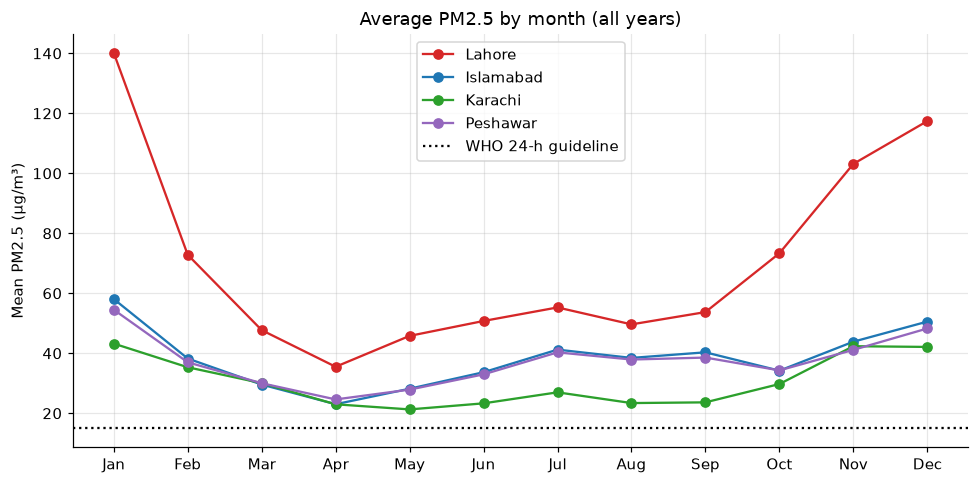

In [18]:
monthly = df.groupby(["city", "month"])["pm2_5"].mean().unstack(0)[CITY_ORDER]
display(monthly.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
for city in CITY_ORDER:
    ax.plot(monthly.index, monthly[city], marker="o", color=CITY_COLORS[city], label=city)
ax.axhline(WHO_24H_PM25, color="black", ls=":", label="WHO 24-h guideline")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("Average PM2.5 by month (all years)")
ax.legend()
save(fig, "04_monthly_pattern")

In [19]:
# Each winter compared: is smog getting better or worse year to year?
season_year = df.assign(season_year=np.where(df["month"] <= 2, df["year"] - 1, df["year"]))
winter = season_year[season_year["is_smog_season"] == 1]
winter.groupby(["season_year", "city"])["pm2_5"].mean().unstack()[CITY_ORDER].round(1) \
      .rename_axis("smog season starting Oct of")

city,Lahore,Islamabad,Karachi,Peshawar
smog season starting Oct of,,,,
2022,115.30,49.20,49.10,45.20
2023,100.60,40.30,38.40,38.40
2024,109.00,47.00,33.70,45.70
2025,110.90,50.10,36.40,48.30
2026,65.50,35.20,29.10,38.10


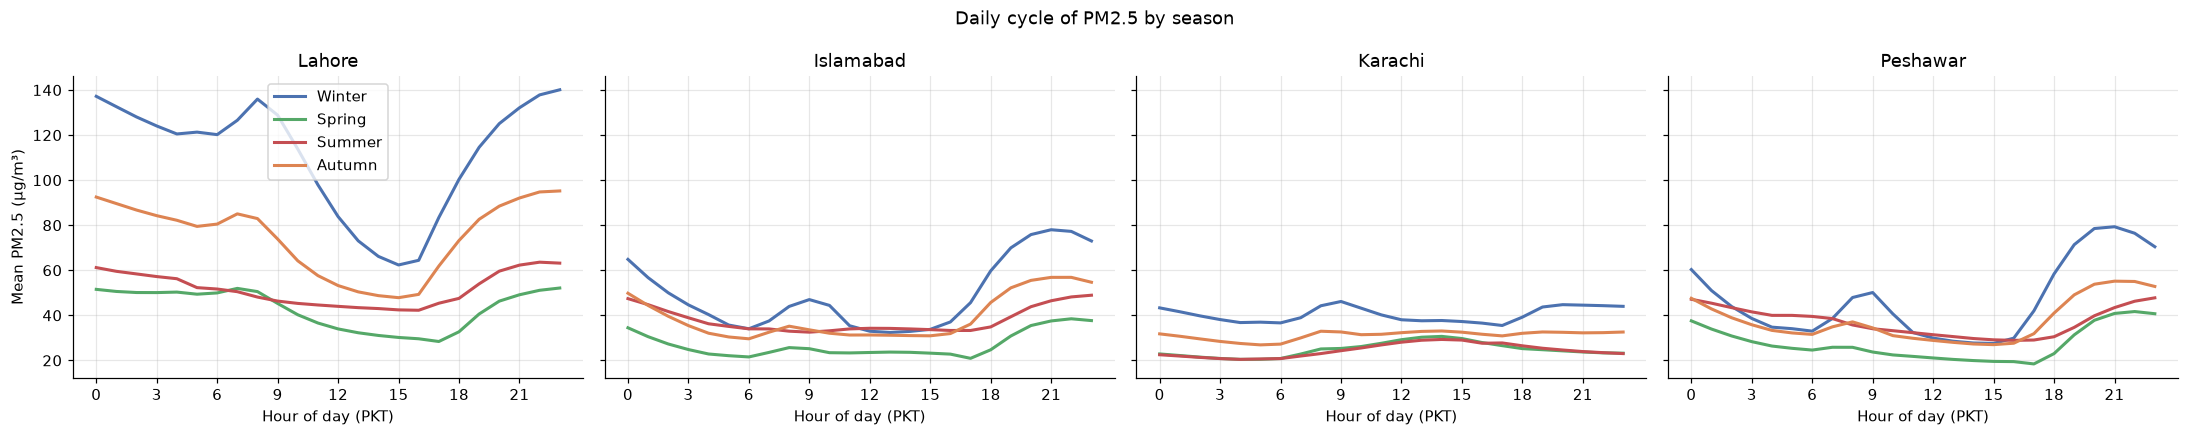

In [20]:
fig, axes = plt.subplots(1, len(CITY_ORDER), figsize=(20, 4), sharey=True)
for ax, city in zip(axes, CITY_ORDER):
    sub = df[df["city"] == city]
    for season, color in [("Winter", "#4c72b0"), ("Spring", "#55a868"),
                          ("Summer", "#c44e52"), ("Autumn", "#dd8452")]:
        prof = sub[sub["season"] == season].groupby("hour")["pm2_5"].mean()
        ax.plot(prof.index, prof.values, label=season, color=color, lw=2)
    ax.set_title(city)
    ax.set_xlabel("Hour of day (PKT)")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("Mean PM2.5 (µg/m³)")
axes[0].legend()
fig.suptitle("Daily cycle of PM2.5 by season")
save(fig, "04_hourly_by_season")

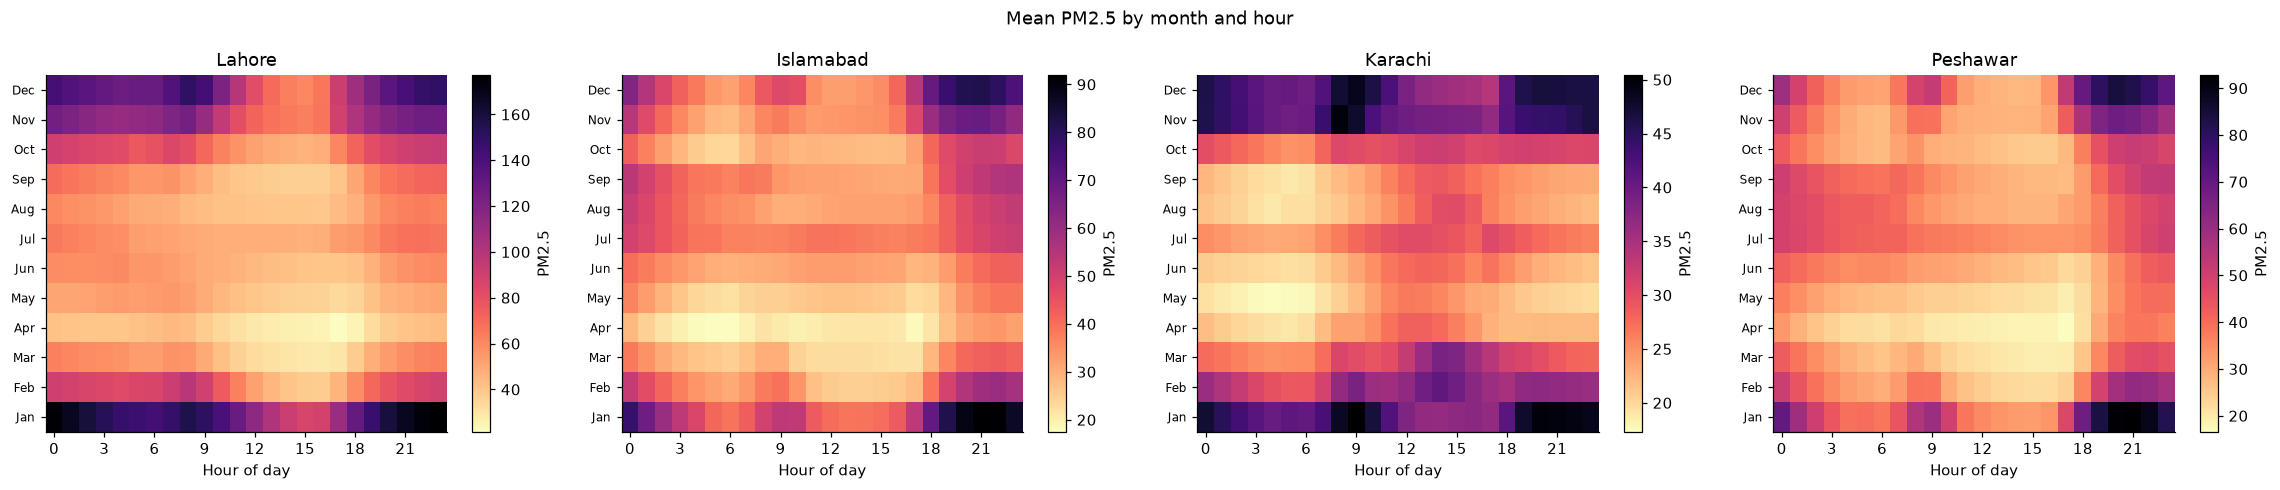

In [21]:
fig, axes = plt.subplots(1, len(CITY_ORDER), figsize=(21, 4.5))
for ax, city in zip(axes, CITY_ORDER):
    grid = df[df["city"] == city].pivot_table(index="month", columns="hour", values="pm2_5", aggfunc="mean")
    im = ax.imshow(grid.values, aspect="auto", cmap="magma_r", origin="lower")
    ax.grid(False)
    ax.set_title(city)
    ax.set_xlabel("Hour of day")
    ax.set_yticks(range(12))
    ax.set_yticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], fontsize=8)
    ax.set_xticks(range(0, 24, 3))
    fig.colorbar(im, ax=ax, label="PM2.5")
fig.suptitle("Mean PM2.5 by month and hour")
save(fig, "04_month_hour_heatmap")

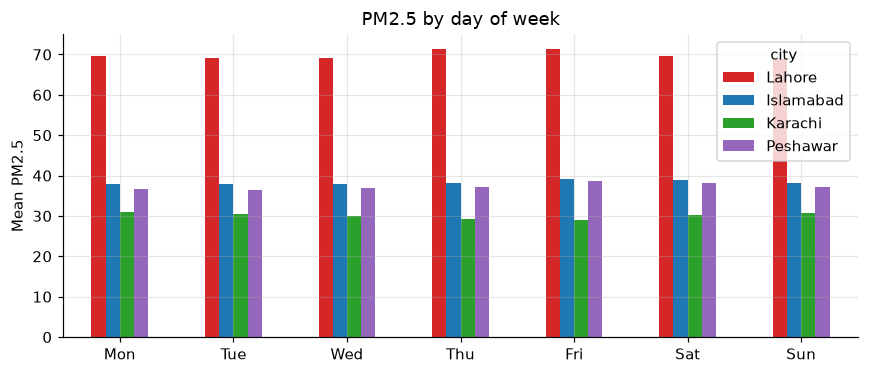

In [22]:
dow = df.groupby(["day_of_week", "city"])["pm2_5"].mean().unstack()[CITY_ORDER]
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(8, 3.5))
dow.plot(kind="bar", ax=ax, color=[CITY_COLORS[c] for c in CITY_ORDER])
ax.set_ylabel("Mean PM2.5")
ax.set_title("PM2.5 by day of week")
plt.xticks(rotation=0)
save(fig, "04_day_of_week")

## Step 5: Relationships between PM2.5 and weather (city comparison)

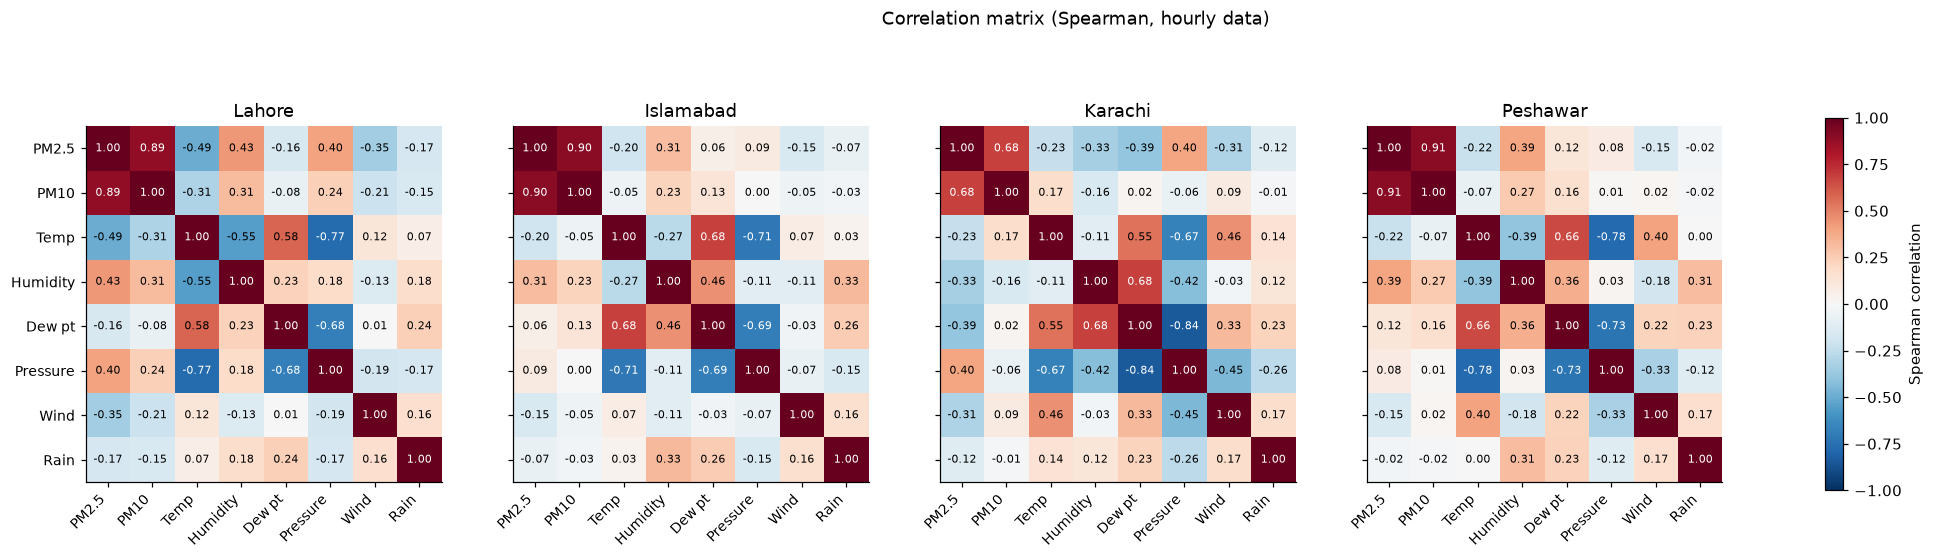

In [23]:
corr_vars = ["pm2_5", "pm10", "temperature_2m", "relative_humidity_2m", "dew_point_2m",
             "surface_pressure", "wind_speed_10m", "precipitation"]
short = ["PM2.5", "PM10", "Temp", "Humidity", "Dew pt", "Pressure", "Wind", "Rain"]
fig, axes = plt.subplots(1, len(CITY_ORDER), figsize=(24, 5.5))
for k, (ax, city) in enumerate(zip(axes, CITY_ORDER)):
    c = df.loc[df["city"] == city, corr_vars].corr(method="spearman")
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.grid(False)
    ax.set_xticks(range(len(corr_vars)))
    ax.set_xticklabels(short, rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(len(corr_vars)))
    ax.set_yticklabels(short if k == 0 else [], fontsize=9)
    for i in range(len(corr_vars)):
        for j in range(len(corr_vars)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(c.iloc[i, j]) > 0.6 else "black")
    ax.set_title(city)
fig.colorbar(im, ax=axes, shrink=0.8, label="Spearman correlation")
fig.suptitle("Correlation matrix (Spearman, hourly data)")
fig.savefig(FIG_DIR / "05_correlation_matrix.png", bbox_inches="tight")
plt.show()

In [24]:
# Correlation of PM2.5 with each weather variable: all year vs smog season only
rows = []
for city in CITY_ORDER:
    sub = df[df["city"] == city]
    for label, part in [("all year", sub), ("smog season", sub[sub["is_smog_season"] == 1])]:
        r = part[corr_vars].corr(method="spearman")["pm2_5"].drop(["pm2_5", "pm10"])
        rows.append(r.rename(f"{city} ({label})"))
pd.DataFrame(rows).round(2)

,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,precipitation
Lahore (all year),-0.49,0.43,-0.16,0.40,-0.35,-0.17
Lahore (smog season),-0.58,0.56,-0.34,0.32,-0.33,-0.09
Islamabad (all year),-0.20,0.31,0.06,0.09,-0.15,-0.07
Islamabad (smog season),-0.38,0.31,-0.18,0.12,-0.10,-0.01
Karachi (all year),-0.23,-0.33,-0.39,0.40,-0.31,-0.12
Karachi (smog season),-0.32,-0.11,-0.25,0.33,-0.13,-0.08
Peshawar (all year),-0.22,0.39,0.12,0.08,-0.15,-0.02
Peshawar (smog season),-0.36,0.39,-0.05,0.16,-0.10,-0.01


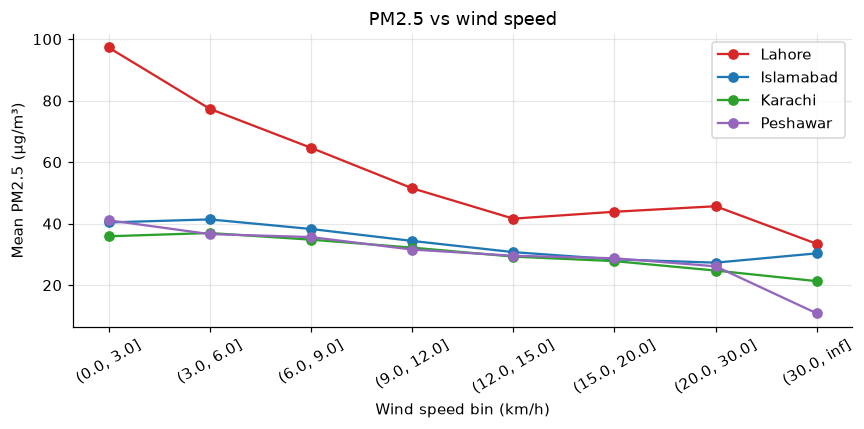

In [25]:
# Mean PM2.5 at different wind speeds: does wind clear the smog?
wind_bins = [0, 3, 6, 9, 12, 15, 20, 30, np.inf]
fig, ax = plt.subplots(figsize=(8, 4))
for city in CITY_ORDER:
    sub = df[df["city"] == city]
    b = pd.cut(sub["wind_speed_10m"], wind_bins)
    m = sub.groupby(b, observed=True)["pm2_5"].mean()
    ax.plot(range(len(m)), m.values, marker="o", color=CITY_COLORS[city], label=city)
ax.set_xticks(range(len(m)))
ax.set_xticklabels([str(i) for i in m.index], rotation=30)
ax.set_xlabel("Wind speed bin (km/h)")
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("PM2.5 vs wind speed")
ax.legend()
save(fig, "05_pm25_vs_wind")

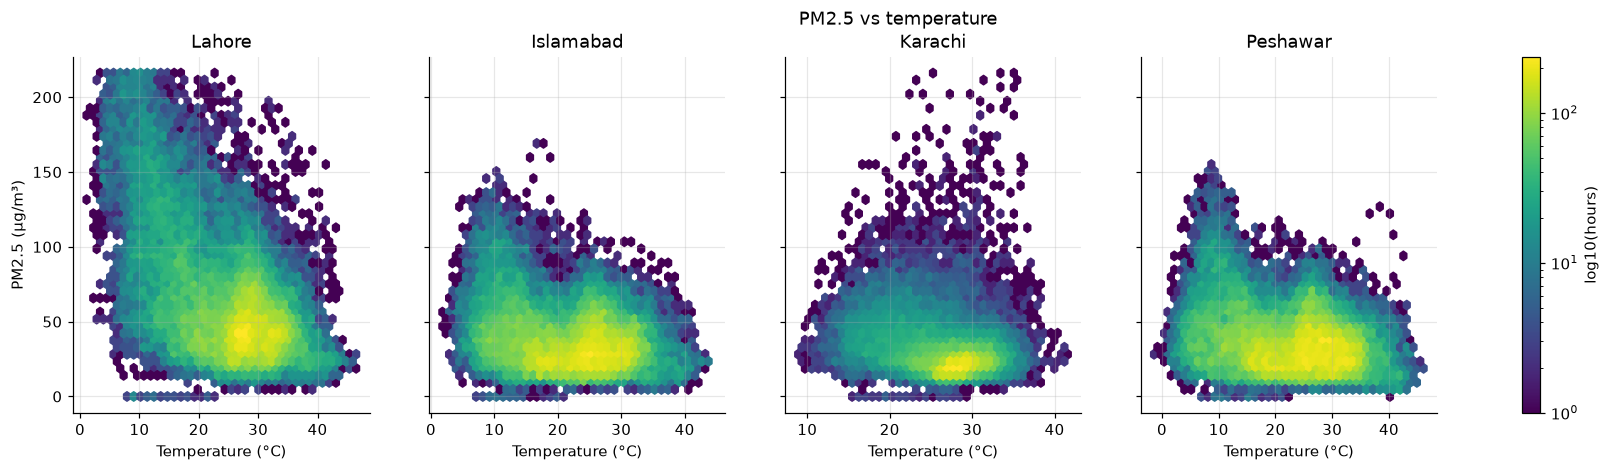

In [26]:
fig, axes = plt.subplots(1, len(CITY_ORDER), figsize=(20, 4.2), sharey=True)
for ax, city in zip(axes, CITY_ORDER):
    sub = df[df["city"] == city]
    hb = ax.hexbin(sub["temperature_2m"], sub["pm2_5"], gridsize=40, bins="log", cmap="viridis",
                   extent=(sub["temperature_2m"].min(), sub["temperature_2m"].max(),
                           0, df["pm2_5"].quantile(0.995)))
    ax.set_title(city)
    ax.set_xlabel("Temperature (°C)")
axes[0].set_ylabel("PM2.5 (µg/m³)")
fig.colorbar(hb, ax=axes, label="log10(hours)")
fig.suptitle("PM2.5 vs temperature")
fig.savefig(FIG_DIR / "05_pm25_vs_temperature.png", bbox_inches="tight")
plt.show()

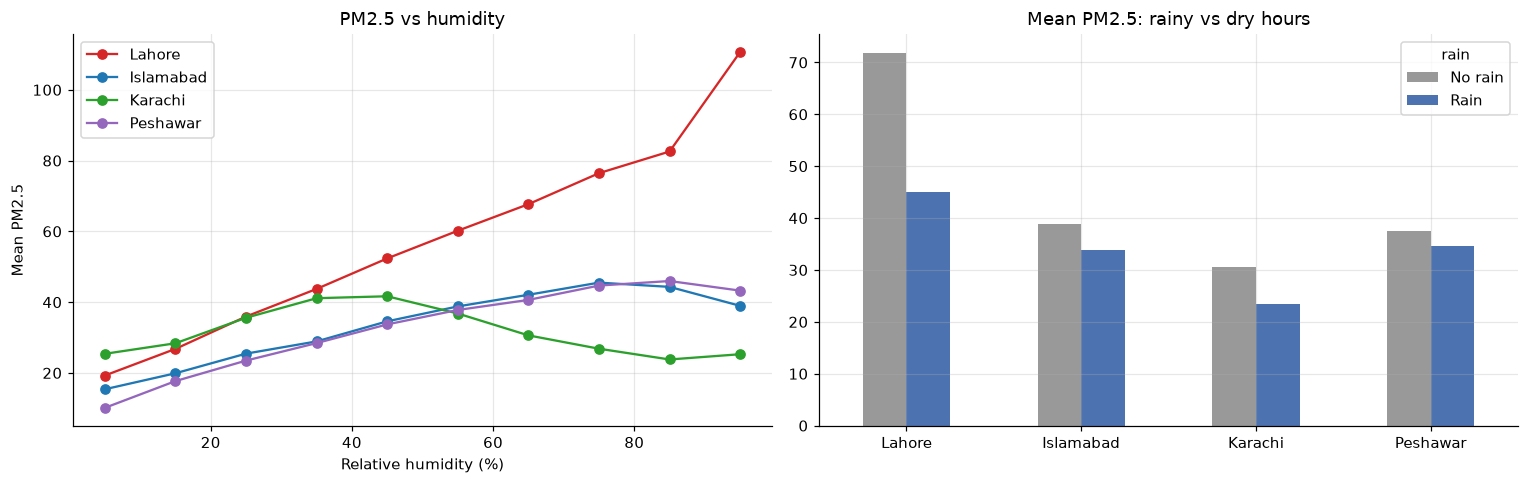

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# humidity
hum_bins = list(range(0, 101, 10))
for city in CITY_ORDER:
    sub = df[df["city"] == city]
    m = sub.groupby(pd.cut(sub["relative_humidity_2m"], hum_bins), observed=True)["pm2_5"].mean()
    axes[0].plot([iv.mid for iv in m.index], m.values, marker="o", color=CITY_COLORS[city], label=city)
axes[0].set_xlabel("Relative humidity (%)")
axes[0].set_ylabel("Mean PM2.5")
axes[0].set_title("PM2.5 vs humidity")
axes[0].legend()
# rain vs no rain
rain = df.assign(rain=np.where(df["precipitation"] > 0, "Rain", "No rain"))
rain.groupby(["city", "rain"])["pm2_5"].mean().unstack().reindex(CITY_ORDER).plot(
    kind="bar", ax=axes[1], color=["#999999", "#4c72b0"])
axes[1].set_title("Mean PM2.5: rainy vs dry hours")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
save(fig, "05_pm25_vs_humidity_rain")

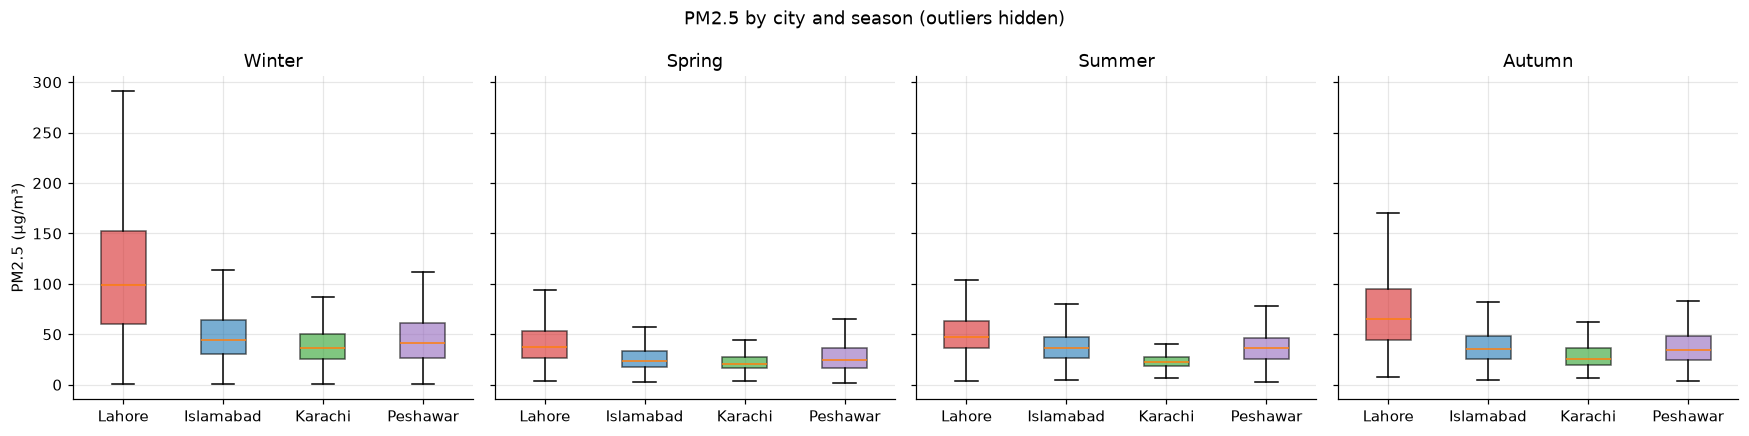

In [28]:
# City comparison by season
season_order = ["Winter", "Spring", "Summer", "Autumn"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, season in zip(axes, season_order):
    data = [df[(df["city"] == c) & (df["season"] == season)]["pm2_5"] for c in CITY_ORDER]
    bp = ax.boxplot(data, tick_labels=CITY_ORDER, showfliers=False, patch_artist=True)
    for patch, c in zip(bp["boxes"], CITY_ORDER):
        patch.set_facecolor(CITY_COLORS[c]); patch.set_alpha(0.6)
    ax.set_title(season)
axes[0].set_ylabel("PM2.5 (µg/m³)")
fig.suptitle("PM2.5 by city and season (outliers hidden)")
save(fig, "05_city_season_boxplot")

In [29]:
# Do the cities move together? Correlation of daily mean PM2.5 between cities
daily_wide = daily.pivot(index="timestamp", columns="city", values="pm2_5")[CITY_ORDER]
daily_wide.corr().round(2)

city,Lahore,Islamabad,Karachi,Peshawar
city,,,,
Lahore,1.00,0.70,0.43,0.62
Islamabad,0.70,1.00,0.32,0.81
Karachi,0.43,0.32,1.00,0.29
Peshawar,0.62,0.81,0.29,1.00


## Step 6: Autocorrelation and lag analysis (for next-day forecasting)
Project 2 will predict **tomorrow's daily mean PM2.5**. Here we check how much of tomorrow is already explained by today and the days before, and which lags are useful as features.

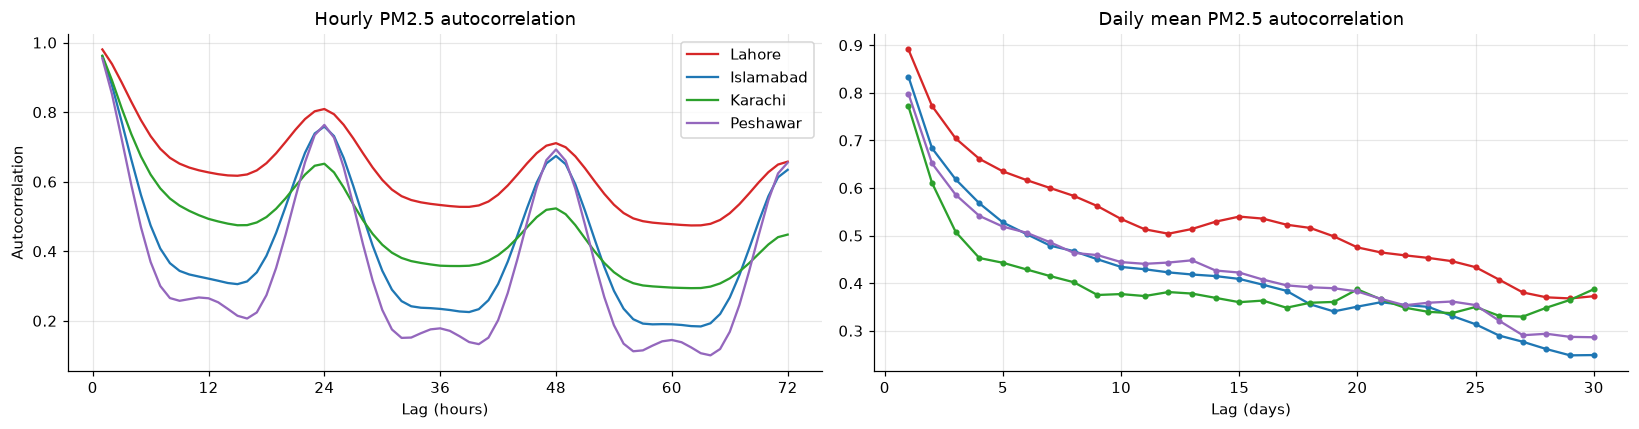

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
# hourly ACF up to 3 days: shows the 24-hour cycle
lags_h = range(1, 73)
for city in CITY_ORDER:
    s = df[df["city"] == city].set_index("timestamp")["pm2_5"].asfreq("h")
    axes[0].plot(list(lags_h), [s.autocorr(l) for l in lags_h], color=CITY_COLORS[city], label=city)
axes[0].set_xticks(range(0, 73, 12))
axes[0].set_xlabel("Lag (hours)")
axes[0].set_ylabel("Autocorrelation")
axes[0].set_title("Hourly PM2.5 autocorrelation")
axes[0].legend()
# daily ACF up to 30 days
lags_d = range(1, 31)
for city in CITY_ORDER:
    s = daily_wide[city]
    axes[1].plot(list(lags_d), [s.autocorr(l) for l in lags_d], marker="o", ms=3,
                 color=CITY_COLORS[city], label=city)
axes[1].set_xlabel("Lag (days)")
axes[1].set_title("Daily mean PM2.5 autocorrelation")
save(fig, "06_autocorrelation")

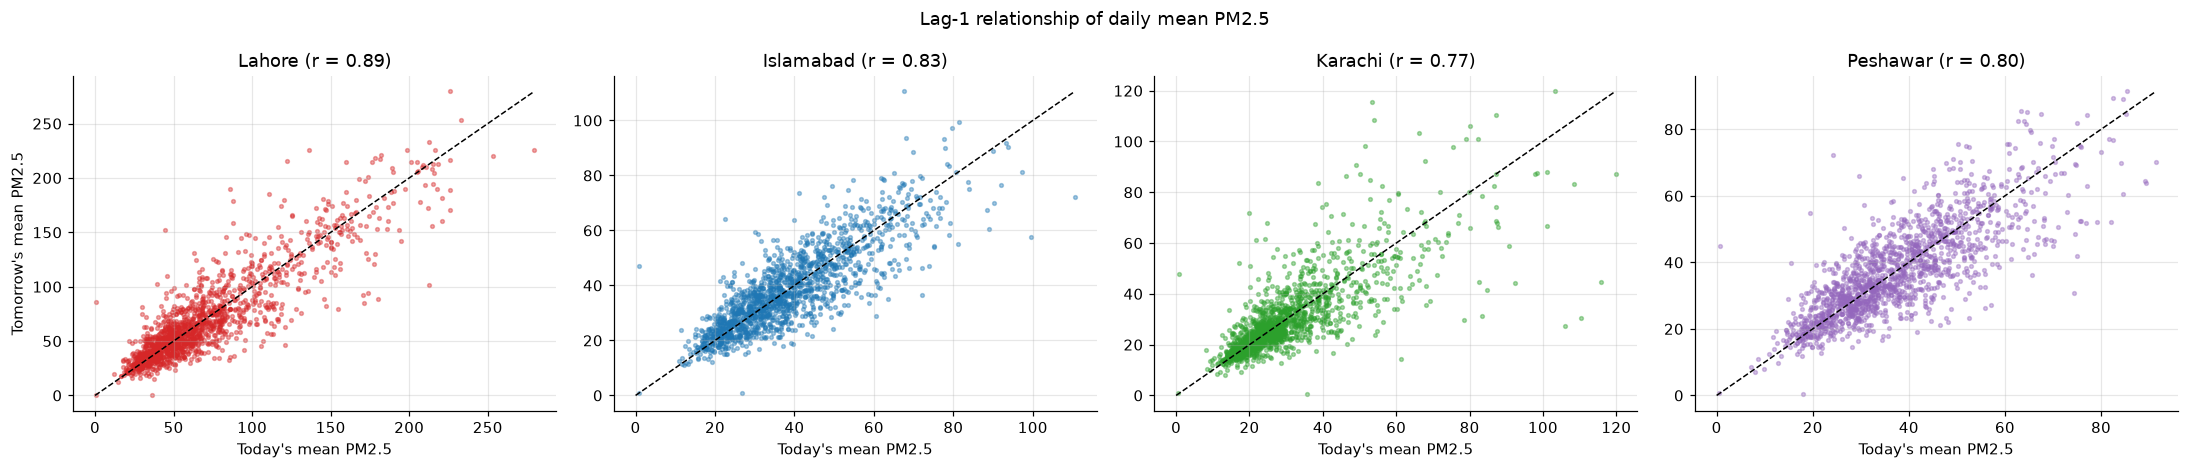

In [31]:
# Today's mean vs tomorrow's mean
fig, axes = plt.subplots(1, len(CITY_ORDER), figsize=(20, 4.3))
for ax, city in zip(axes, CITY_ORDER):
    s = daily_wide[city].dropna()
    today, tomorrow = s[:-1].values, s[1:].values
    ax.scatter(today, tomorrow, s=6, alpha=0.4, color=CITY_COLORS[city])
    lim = max(today.max(), tomorrow.max())
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    ax.set_title(f"{city} (r = {np.corrcoef(today, tomorrow)[0, 1]:.2f})")
    ax.set_xlabel("Today's mean PM2.5")
axes[0].set_ylabel("Tomorrow's mean PM2.5")
fig.suptitle("Lag-1 relationship of daily mean PM2.5")
save(fig, "06_lag1_scatter")

In [32]:
# Simple baselines that the Project 2 model has to beat
rows = []
for city in CITY_ORDER:
    s = daily_wide[city].dropna()
    target = s.shift(-1)                     # tomorrow's mean
    baselines = {
        "persistence (tomorrow = today)": s,
        "7-day mean": s.rolling(7).mean(),
        "same month average": s.groupby(s.index.month).transform("mean"),
    }
    for name, pred in baselines.items():
        ok = target.notna() & pred.notna()
        err = target[ok] - pred[ok]
        rows.append({"city": city, "baseline": name,
                     "MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean())})
baseline_table = pd.DataFrame(rows).pivot(index="baseline", columns="city", values="MAE")[CITY_ORDER]
print("MAE (µg/m³) of next-day daily mean PM2.5 forecasts")
baseline_table.round(2)

MAE (µg/m³) of next-day daily mean PM2.5 forecasts


city,Lahore,Islamabad,Karachi,Peshawar
baseline,,,,
7-day mean,18.16,8.05,7.72,7.63
persistence (tomorrow = today),13.51,6.33,6.15,6.51
same month average,20.58,9.14,8.39,8.96


In [33]:
# Which past information correlates with tomorrow's mean? (candidate features for Project 2)
rows = []
for city in CITY_ORDER:
    sub = df[df["city"] == city].set_index("timestamp")
    d = sub[["pm2_5", "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
             "surface_pressure", "precipitation"]].resample("D").mean()
    target = d["pm2_5"].shift(-1)
    feats = {
        "pm2_5 today (lag 1)": d["pm2_5"],
        "pm2_5 lag 2": d["pm2_5"].shift(1),
        "pm2_5 lag 7": d["pm2_5"].shift(6),
        "pm2_5 3-day mean": d["pm2_5"].rolling(3).mean(),
        "temperature today": d["temperature_2m"],
        "humidity today": d["relative_humidity_2m"],
        "wind speed today": d["wind_speed_10m"],
        "pressure today": d["surface_pressure"],
        "rain today": d["precipitation"],
    }
    rows.append({name: target.corr(f, method="spearman") for name, f in feats.items()} | {"city": city})
pd.DataFrame(rows).set_index("city").T.round(2)

city,Lahore,Islamabad,Karachi,Peshawar
pm2_5 today (lag 1),0.85,0.83,0.81,0.80
pm2_5 lag 2,0.71,0.67,0.66,0.66
pm2_5 lag 7,0.58,0.50,0.46,0.49
pm2_5 3-day mean,0.79,0.75,0.73,0.75
temperature today,-0.47,-0.21,-0.38,-0.21
humidity today,0.30,0.22,-0.38,0.27
wind speed today,-0.50,-0.32,-0.42,-0.27
pressure today,0.49,0.19,0.45,0.16
rain today,-0.32,-0.09,-0.28,-0.07


## Summary numbers
The cell below prints the key numbers from this analysis so they can be quoted directly in the report.

In [34]:
print("Dataset")
print(f"  {len(df):,} clean hourly rows, {df['timestamp'].min():%d %b %Y} to {df['timestamp'].max():%d %b %Y}")
print(f"  {len(rejected):,} rows rejected by Pydantic validation, "
      f"{int(df['is_interpolated'].sum()):,} rows with interpolated values\n")

for city in CITY_ORDER:
    sub = df[df["city"] == city]
    d = daily_wide[city].dropna()
    worst_month = monthly[city].idxmax()
    best_month = monthly[city].idxmin()
    print(city)
    print(f"  mean PM2.5 {sub['pm2_5'].mean():.1f} µg/m³, median {sub['pm2_5'].median():.1f}")
    print(f"  worst month {worst_month} ({monthly[city].max():.0f}), cleanest month {best_month} ({monthly[city].min():.0f})")
    print(f"  smog season mean {sub[sub['is_smog_season']==1]['pm2_5'].mean():.1f} vs rest of year "
          f"{sub[sub['is_smog_season']==0]['pm2_5'].mean():.1f}")
    print(f"  days above WHO 24-h guideline: {(d > WHO_24H_PM25).mean()*100:.0f}%")
    print(f"  hours 'Unhealthy' or worse: "
          f"{sub['aqi_category'].isin(['Unhealthy','Very Unhealthy','Hazardous']).mean()*100:.1f}%")
    print(f"  lag-1 daily autocorrelation: {d.autocorr(1):.2f}")
    print(f"  persistence baseline MAE: {baseline_table.loc['persistence (tomorrow = today)', city]:.1f} µg/m³\n")

Dataset
  148,105 clean hourly rows, 04 Aug 2022 to 24 Oct 2026
  6 rows rejected by Pydantic validation, 3 rows with interpolated values

Lahore
  mean PM2.5 69.9 µg/m³, median 54.8
  worst month 1 (140), cleanest month 4 (36)
  smog season mean 106.9 vs rest of year 51.3
  days above WHO 24-h guideline: 100%
  hours 'Unhealthy' or worse: 49.2%
  lag-1 daily autocorrelation: 0.89
  persistence baseline MAE: 13.5 µg/m³

Islamabad
  mean PM2.5 38.3 µg/m³, median 34.2
  worst month 1 (58), cleanest month 4 (23)
  smog season mean 46.1 vs rest of year 34.4
  days above WHO 24-h guideline: 99%
  hours 'Unhealthy' or worse: 16.8%
  lag-1 daily autocorrelation: 0.83
  persistence baseline MAE: 6.3 µg/m³

Karachi
  mean PM2.5 30.1 µg/m³, median 25.0
  worst month 1 (43), cleanest month 5 (21)
  smog season mean 38.9 vs rest of year 25.7
  days above WHO 24-h guideline: 95%
  hours 'Unhealthy' or worse: 7.8%
  lag-1 daily autocorrelation: 0.77
  persistence baseline MAE: 6.1 µg/m³

Peshawar
  

## Key findings
*Write these in your own words after running the notebook on the real data, using the numbers printed above. Guiding questions:*

1. **Data quality:** how much data was missing or rejected, and did cleaning leave any gaps?
2. **City comparison:** which city is most polluted, and by how much?
3. **Seasonality:** which months are worst, and how much higher is the smog season than the rest of the year?
4. **Daily cycle:** at what hours does PM2.5 peak in winter, and why might that be (low night-time mixing, evening traffic, burning)?
5. **Weather:** how do wind speed, temperature, humidity and rain relate to PM2.5, and are the relationships stronger in the smog season?
6. **Forecasting:** how strongly does today predict tomorrow, and what MAE does the persistence baseline give? This is the number the Project 2 model must beat.

**Limitation to mention:** PM2.5 values are CAMS model estimates from Open-Meteo, not ground-sensor measurements. They are used because ground-sensor data in Pakistan is sparse, but they can under- or over-estimate local extremes.

In [35]:
conn.close()